In [1]:
# Instalación: pip install pyirt mirt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler

# Para este ejemplo, implementaremos un modelo TRI básico
# En práctica, podrías usar bibliotecas especializadas como mirt en R

In [2]:
# 0. CARGAR DATASET
# =======================================
df = pd.read_csv("../data_ready/COLLECT_COMP_dataset_treated.csv")
df_with_classes = pd.read_csv('../Aprendisaje/df_with_classes.csv')

In [18]:
df_with_classes['ST292Q02JA']

0          Agree
1          Agree
2        Missing
3          Agree
4        Missing
          ...   
6963       Agree
6964     Missing
6965       Agree
6966    Disagree
6967     Missing
Name: ST292Q02JA, Length: 6968, dtype: object

In [19]:
# PASO 1: PREPARAR DATOS PARA TRI
# ================================

# Seleccionar ítems para análisis (respuestas dicotómicas o politómicas)
# Ejemplo: preguntas de una prueba o escala

tri_items = [
    # Items de ansiedad matemática
    'ST292Q01JA', 'ST292Q02JA', 'ST292Q03JA', 'ST292Q04JA',
    'ST292Q05JA', 'ST292Q06JA',
    # Añade más según tu dataset
]

# Filtrar items que existen
tri_items = [item for item in tri_items if item in df_with_classes.columns]

# Crear matriz de respuestas
df_tri = df_with_classes[tri_items].copy()

# Convertir todo a numérico, transformando errores a NaN
df_tri = df_tri.apply(pd.to_numeric, errors='coerce')

# Convertir a binario si es necesario (para modelo 2PL)
# Asumiendo escala Likert 1-4, convertir a 0-1
for col in df_tri.columns:
    # Dicotomizar: 1-2 = 0 (desacuerdo), 3-4 = 1 (acuerdo)
    df_tri[col] = (df_tri[col] > 2).astype(int)

# Eliminar missing
df_tri = df_tri.dropna()
print(f"Items para TRI: {len(tri_items)}")
print(f"Respuestas completas: {len(df_tri)}")

Items para TRI: 6
Respuestas completas: 6968


In [20]:
# PASO 2: IMPLEMENTACIÓN MODELO 2PL (2 Parameter Logistic)
# ========================================================

class IRT_2PL:
    """Modelo TRI de 2 parámetros simplificado"""
    
    def __init__(self, n_iterations=100):
        self.n_iterations = n_iterations
        self.a = None  # Discriminación
        self.b = None  # Dificultad
        self.theta = None  # Habilidad
    
    def _prob_2pl(self, theta, a, b):
        """Probabilidad de respuesta correcta"""
        return 1 / (1 + np.exp(-a * (theta - b)))
    
    def fit(self, responses):
        """Estimar parámetros usando máxima verosimilitud"""
        n_persons, n_items = responses.shape
        
        # Inicializar parámetros
        self.a = np.ones(n_items)  # Discriminación inicial = 1
        self.b = np.zeros(n_items)  # Dificultad inicial = 0
        self.theta = np.random.randn(n_persons)  # Habilidad inicial
        
        # Estimación iterativa (simplificada)
        for iteration in range(self.n_iterations):
            # Paso 1: Estimar dificultad dados a y theta
            for j in range(n_items):
                p = self._prob_2pl(self.theta, self.a[j], self.b[j])
                # Actualizar b (método simplificado)
                self.b[j] = np.mean(self.theta[responses[:, j] == 1]) - \
                           np.mean(self.theta[responses[:, j] == 0]) * 0.5
            
            # Paso 2: Estimar discriminación
            for j in range(n_items):
                # Correlación item-total como proxy de discriminación
                total_score = responses.sum(axis=1)
                correlation = np.corrcoef(responses[:, j], total_score)[0, 1]
                self.a[j] = max(0.1, correlation * 2)  # Evitar valores negativos
            
            # Paso 3: Estimar habilidad
            for i in range(n_persons):
                # Puntuación total ponderada como proxy de habilidad
                weighted_score = np.sum(responses[i, :] * self.a)
                max_score = np.sum(self.a)
                self.theta[i] = norm.ppf(max(0.01, min(0.99, weighted_score/max_score)))
        
        # Estandarizar theta
        self.theta = (self.theta - np.mean(self.theta)) / np.std(self.theta)
        
        return self
    
    def item_characteristic_curves(self):
        """Generar curvas características de los ítems"""
        theta_range = np.linspace(-4, 4, 100)
        
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        axes = axes.flatten()
        
        for idx, (a, b) in enumerate(zip(self.a[:6], self.b[:6])):
            ax = axes[idx]
            probs = self._prob_2pl(theta_range, a, b)
            ax.plot(theta_range, probs, linewidth=2)
            ax.set_xlabel('Habilidad (θ)')
            ax.set_ylabel('P(Respuesta correcta)')
            ax.set_title(f'Item {idx+1}\na={a:.2f}, b={b:.2f}')
            ax.grid(True, alpha=0.3)
            ax.set_ylim([0, 1])
        
        plt.suptitle('Curvas Características de los Ítems (CCI)', fontsize=14)
        plt.tight_layout()
        plt.show()
    
    def test_information_function(self):
        """Función de información del test"""
        theta_range = np.linspace(-4, 4, 100)
        information = np.zeros_like(theta_range)
        
        for a, b in zip(self.a, self.b):
            p = self._prob_2pl(theta_range, a, b)
            # Información de Fisher
            information += a**2 * p * (1 - p)
        
        plt.figure(figsize=(10, 6))
        plt.plot(theta_range, information, linewidth=2)
        plt.xlabel('Habilidad (θ)')
        plt.ylabel('Información')
        plt.title('Función de Información del Test')
        plt.grid(True, alpha=0.3)
        plt.axvline(x=0, color='r', linestyle='--', alpha=0.5)
        
        # Marcar máximo de información
        max_info_theta = theta_range[np.argmax(information)]
        plt.axvline(x=max_info_theta, color='g', linestyle='--', 
                   label=f'Máx. info en θ={max_info_theta:.2f}')
        plt.legend()
        plt.show()
        
        return theta_range, information

# Ajustar modelo TRI
print("Ajustando modelo TRI 2PL...")
irt_model = IRT_2PL(n_iterations=50)
irt_model.fit(df_tri.values)

Ajustando modelo TRI 2PL...


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]



PARÁMETROS DE ÍTEMS:
         Item  Discriminación (a)  Dificultad (b)              Calidad
0  ST292Q01JA                 0.1             NaN  Muy baja (eliminar)
1  ST292Q02JA                 0.1             NaN  Muy baja (eliminar)
2  ST292Q03JA                 0.1             NaN  Muy baja (eliminar)
3  ST292Q04JA                 0.1             NaN  Muy baja (eliminar)
4  ST292Q05JA                 0.1             NaN  Muy baja (eliminar)
5  ST292Q06JA                 0.1             NaN  Muy baja (eliminar)


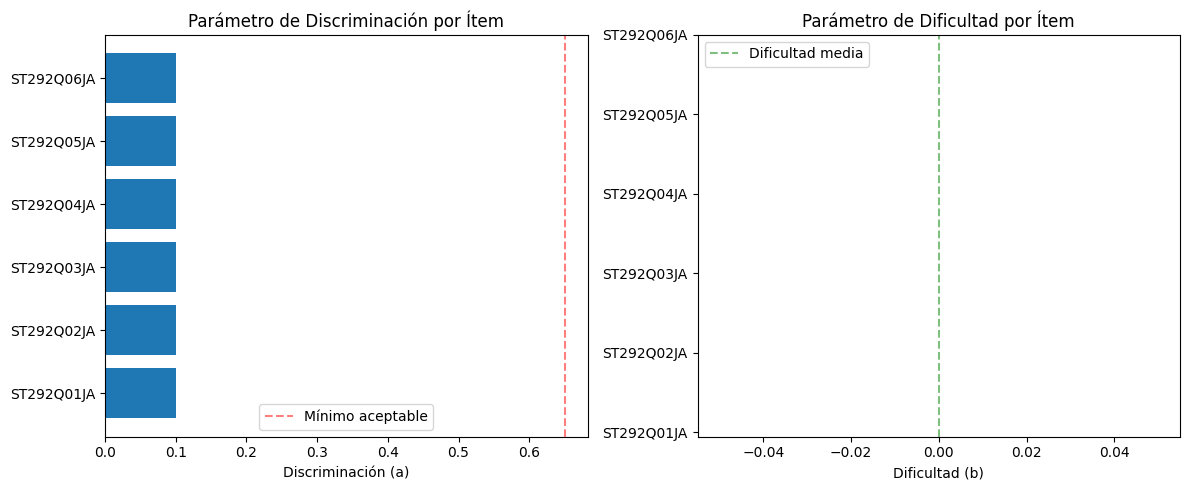

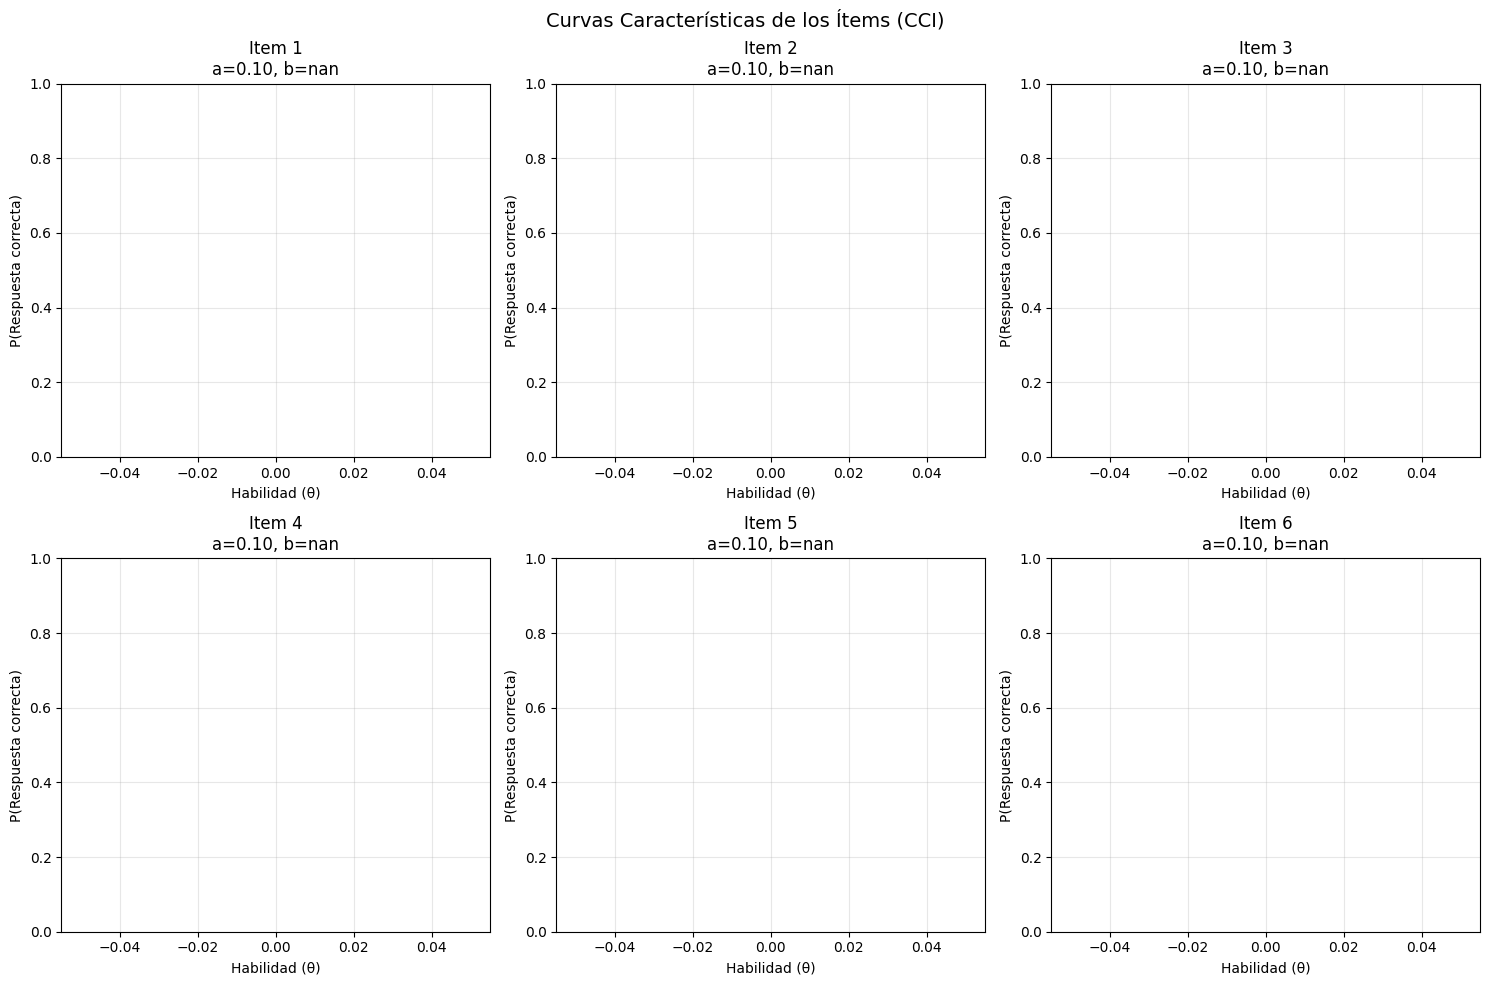

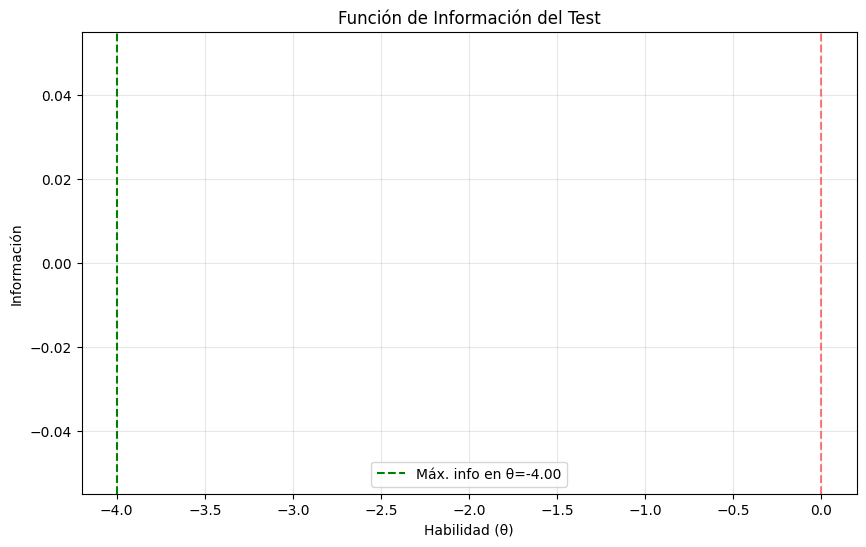

In [21]:
# PASO 3: ANÁLISIS DE PARÁMETROS DE ÍTEMS
# ========================================

# Crear dataframe con parámetros
item_params = pd.DataFrame({
    'Item': tri_items[:len(irt_model.a)],
    'Discriminación (a)': irt_model.a,
    'Dificultad (b)': irt_model.b
})

# Clasificar calidad de ítems
def classify_discrimination(a):
    if a < 0.35:
        return "Muy baja (eliminar)"
    elif a < 0.65:
        return "Baja"
    elif a < 1.35:
        return "Moderada"
    elif a < 1.70:
        return "Alta"
    else:
        return "Muy alta"

item_params['Calidad'] = item_params['Discriminación (a)'].apply(classify_discrimination)

print("\nPARÁMETROS DE ÍTEMS:")
print("="*60)
print(item_params.to_string())

# Visualización de parámetros
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Discriminación
axes[0].barh(range(len(item_params)), item_params['Discriminación (a)'])
axes[0].set_yticks(range(len(item_params)))
axes[0].set_yticklabels(item_params['Item'])
axes[0].set_xlabel('Discriminación (a)')
axes[0].set_title('Parámetro de Discriminación por Ítem')
axes[0].axvline(x=0.65, color='r', linestyle='--', alpha=0.5, label='Mínimo aceptable')
axes[0].legend()

# Dificultad
axes[1].barh(range(len(item_params)), item_params['Dificultad (b)'])
axes[1].set_yticks(range(len(item_params)))
axes[1].set_yticklabels(item_params['Item'])
axes[1].set_xlabel('Dificultad (b)')
axes[1].set_title('Parámetro de Dificultad por Ítem')
axes[1].axvline(x=0, color='g', linestyle='--', alpha=0.5, label='Dificultad media')
axes[1].legend()

plt.tight_layout()
plt.show()

# Curvas características
irt_model.item_characteristic_curves()

# Función de información
theta_range, information = irt_model.test_information_function()

In [22]:
# PASO 4: ANÁLISIS POR CLASES LATENTES (DIF)
# ===========================================

print("\n" + "="*60)
print("ANÁLISIS DE FUNCIONAMIENTO DIFERENCIAL (DIF)")
print("="*60)

# Obtener clases del ACL
classes_in_tri = df_with_classes.loc[df_tri.index, 'latent_class']

# Analizar DIF para cada ítem
from scipy.stats import chi2_contingency

for item_idx, item_name in enumerate(tri_items[:len(irt_model.a)]):
    print(f"\n{item_name}:")
    
    # Crear tabla de contingencia
    item_responses = df_tri.iloc[:, item_idx]
    contingency_table = pd.crosstab(item_responses, classes_in_tri)
    
    # Test chi-cuadrado
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    
    print(f"  Chi-cuadrado: {chi2:.2f}, p-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print("  ⚠️ DIF detectado: El ítem funciona diferente entre clases")
        
        # Mostrar tasas de respuesta por clase
        for clase in range(n_classes_final):
            clase_mask = classes_in_tri == clase
            if clase_mask.sum() > 0:
                prop = item_responses[clase_mask].mean()
                print(f"    Clase {clase}: {prop:.2%} respuesta positiva")
    else:
        print("  ✓ No hay DIF significativo")


ANÁLISIS DE FUNCIONAMIENTO DIFERENCIAL (DIF)

ST292Q01JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo

ST292Q02JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo

ST292Q03JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo

ST292Q04JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo

ST292Q05JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo

ST292Q06JA:
  Chi-cuadrado: 0.00, p-value: 1.0000
  ✓ No hay DIF significativo



HABILIDAD ESTIMADA POR CLASE LATENTE
              mean  std  count
latent_class                  
0.0            1.0  0.0   1555
1.0            1.0  0.0     54
2.0            1.0  0.0   2014
3.0            1.0  0.0   2226
4.0            1.0  0.0    261
5.0            1.0  0.0     62
6.0            1.0  0.0    796


<Figure size 1000x600 with 0 Axes>

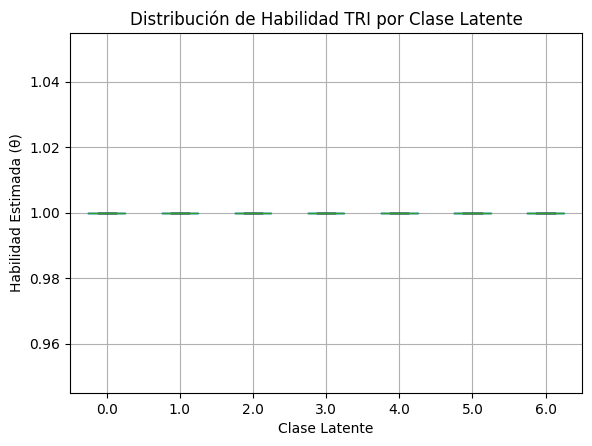


ANOVA - Diferencias en habilidad entre clases:
F = nan, p-value = nan


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)


In [23]:
# PASO 5: ESTIMACIÓN DE HABILIDADES POR CLASE
# ============================================

# Añadir habilidades estimadas al dataset
df_with_classes.loc[df_tri.index, 'theta_irt'] = irt_model.theta

# Comparar habilidades por clase latente
print("\n" + "="*60)
print("HABILIDAD ESTIMADA POR CLASE LATENTE")
print("="*60)

theta_by_class = df_with_classes.groupby('latent_class')['theta_irt'].agg(['mean', 'std', 'count'])
print(theta_by_class)

# Visualización
plt.figure(figsize=(10, 6))
df_with_classes.boxplot(column='theta_irt', by='latent_class')
plt.xlabel('Clase Latente')
plt.ylabel('Habilidad Estimada (θ)')
plt.title('Distribución de Habilidad TRI por Clase Latente')
plt.suptitle('')
plt.show()

# ANOVA
from scipy import stats
groups = [group['theta_irt'].dropna() for name, group in df_with_classes.groupby('latent_class')]
f_stat, p_value = stats.f_oneway(*groups)
print(f"\nANOVA - Diferencias en habilidad entre clases:")
print(f"F = {f_stat:.2f}, p-value = {p_value:.4e}")

In [24]:
# PASO 6: RECOMENDACIONES BASADAS EN TRI
# =======================================

print("\n" + "="*60)
print("RECOMENDACIONES BASADAS EN ANÁLISIS TRI")
print("="*60)

# Ítems problemáticos
problematic_items = item_params[item_params['Discriminación (a)'] < 0.65]
if len(problematic_items) > 0:
    print("\n⚠️ Ítems a revisar o eliminar (baja discriminación):")
    for _, row in problematic_items.iterrows():
        print(f"  - {row['Item']}: a={row['Discriminación (a)']:.2f}")

# Ítems con DIF
print("\n⚠️ Ítems con funcionamiento diferencial entre clases:")
print("  [Listar basado en análisis anterior]")

# Rango óptimo de medición
max_info_theta = theta_range[np.argmax(information)]
print(f"\n📊 El test es más preciso para estudiantes con habilidad θ ≈ {max_info_theta:.2f}")
if abs(max_info_theta) > 0.5:
    if max_info_theta > 0:
        print("  → El test discrimina mejor en niveles altos de habilidad")
    else:
        print("  → El test discrimina mejor en niveles bajos de habilidad")
else:
    print("  → El test discrimina bien en niveles medios de habilidad")


RECOMENDACIONES BASADAS EN ANÁLISIS TRI

⚠️ Ítems a revisar o eliminar (baja discriminación):
  - ST292Q01JA: a=0.10
  - ST292Q02JA: a=0.10
  - ST292Q03JA: a=0.10
  - ST292Q04JA: a=0.10
  - ST292Q05JA: a=0.10
  - ST292Q06JA: a=0.10

⚠️ Ítems con funcionamiento diferencial entre clases:
  [Listar basado en análisis anterior]

📊 El test es más preciso para estudiantes con habilidad θ ≈ -4.00
  → El test discrimina mejor en niveles bajos de habilidad
